# 🚀 Practice Day 24

**📅 Date:** 2026-11-12  
📁 Category: Phase 3 · NumPy+통계 응용 (Round 2/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Apply core statistics (mean, standard error, z-score, confidence interval) to compare two experiment groups, the way an A/B test analysis would
  (평균·표준오차·z-score·신뢰구간 같은 통계 개념을 두 실험 그룹 비교에 적용해보기 — 실제 A/B 테스트 분석 방식)
- Find out whether the new landing page (Group B) actually performs better than the original (Group A), not just whether the numbers look bigger
  (새 랜딩페이지(B그룹)가 숫자만 커 보이는 게 아니라 실제로 더 나은 성과인지 통계적으로 확인하기)

---
# 📂 Dataset

**Dataset Name:** Landing Page A/B Test — 웹사이트 랜딩페이지 A/B 테스트 결과

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Results from an A/B test of a website landing page across 400 visitors (Group A: 200, the original page; Group B: 200, the new design). Includes each visitor's session duration, pages viewed, and whether they converted (0/1). Clean — no missing values or duplicates. The focus is on statistically comparing the two groups, not just eyeballing the raw numbers.
(400명의 방문자를 대상으로 진행한 랜딩페이지 A/B 테스트 결과입니다(A그룹 200명 = 기존 페이지, B그룹 200명 = 새 디자인). 방문자별 세션 체류시간, 조회 페이지 수, 전환 여부(0/1)를 담고 있으며 결측치·중복 없이 깨끗합니다. 두 그룹을 통계적으로 비교하는 데 초점을 둡니다.)

## Dataset Preview

In [26]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate a landing-page A/B test: Group A (original) vs Group B (new design) ---
n_a, n_b = 200, 200

dur_a = np.clip(rng.normal(180, 60, n_a), 15, 620).round().astype(int)
pages_a = np.clip(rng.poisson(3.2, n_a), 1, 15)
conv_a = rng.binomial(1, 0.08, n_a)

dur_b = np.clip(rng.normal(212, 65, n_b), 15, 620).round().astype(int)
pages_b = np.clip(rng.poisson(3.8, n_b), 1, 15)
conv_b = rng.binomial(1, 0.16, n_b)

df = pd.DataFrame({
    'visitor_id': [f'V{str(i+1).zfill(4)}' for i in range(n_a + n_b)],
    'group': ['A'] * n_a + ['B'] * n_b,
    'session_duration_sec': np.concatenate([dur_a, dur_b]),
    'pages_viewed': np.concatenate([pages_a, pages_b]),
    'converted': np.concatenate([conv_a, conv_b])
})
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,visitor_id,group,session_duration_sec,pages_viewed,converted
0,V0062,A,160,3,0
1,V0349,B,362,5,0
2,V0164,A,131,1,0
3,V0008,A,161,3,0
4,V0276,B,188,3,0
5,V0382,B,231,3,0
6,V0209,B,168,5,0
7,V0004,A,236,5,0
8,V0257,B,232,2,0
9,V0168,A,203,1,0


## Dataset Information

In [27]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   visitor_id            400 non-null    str  
 1   group                 400 non-null    str  
 2   session_duration_sec  400 non-null    int64
 3   pages_viewed          400 non-null    int64
 4   converted             400 non-null    int64
dtypes: int64(3), str(2)
memory usage: 15.8 KB

Shape: (400, 5)


,visitor_id,group,session_duration_sec,pages_viewed,converted
count,400,400,400.000000,400.00000,400.000000
unique,400,2,NaN,NaN,NaN
top,V0062,A,NaN,NaN,NaN
freq,1,200,NaN,NaN,NaN
mean,NaN,NaN,193.682500,3.48750,0.102500
std,NaN,NaN,63.626035,1.79664,0.303685
min,NaN,NaN,26.000000,1.00000,0.000000
25%,NaN,NaN,152.000000,2.00000,0.000000
50%,NaN,NaN,191.000000,3.00000,0.000000
75%,NaN,NaN,236.000000,5.00000,0.000000


---
# ❓ Business Questions

1. **(Analysis)** How much longer (or shorter) is the average session duration for Group B vs Group A, and is that difference statistically significant (z-score)?
   (B그룹과 A그룹의 평균 세션 체류시간 차이는 얼마이며, 그 차이는 통계적으로 유의한가(z-score)?)
2. **(Analysis)** How much higher is Group B's conversion rate compared to Group A, and does the 95% confidence interval for that difference exclude zero?
   (B그룹의 전환율은 A그룹보다 얼마나 높으며, 그 차이의 95% 신뢰구간은 0을 포함하지 않는가?)
3. **(Analysis)** How does the distribution of pages viewed differ between the two groups (mean, spread)?
   (두 그룹의 조회 페이지 수 분포는 평균과 산포 측면에서 어떻게 다른가?)
4. **(Visualization)** Compare the distribution of session duration between the two groups.
   (두 그룹의 세션 체류시간 분포를 비교하면?)
5. **(Visualization)** Compare the conversion rate between the two groups.
   (두 그룹의 전환율을 비교하면?)

---
# 🛠 Skills Used
- [x] Python — f-strings, boolean mask  
 (f-string 출력, 불리언 마스크)  
- [x] NumPy — `np.mean`, `np.std`, `np.sqrt`  
 (평균, 표준편차, 제곱근)  
- [x] Pandas — column selection, boolean filter  
 (컬럼 선택, 조건 필터)  
- [ ] SQL  
- [x] Matplotlib — `plt.subplots`, axis formatter  
 (그림 만들기, 축 형식)  
- [x] Other: Seaborn — `boxplot`, `barplot`  
 (박스플롯, 막대그래프)  

---
# 🔍 Data Cleaning Check

Things I checked:
- [x] Missing Values — **0** in every column  
 (모든 컬럼에서 결측치 **0**)  
- [x] Duplicate Rows — **0**  
 (중복 행 **0**)  
- [x] Wrong Data Types — all numeric columns are `int64`, text columns are `str`  
 (숫자 컬럼은 모두 `int64`, 텍스트 컬럼은 `str`)  
- [ ] Rename Columns — not needed  
- [ ] Drop Columns — not needed  


In [28]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
visitor_id              0
group                   0
session_duration_sec    0
pages_viewed            0
converted               0
dtype: int64

Duplicate rows: 0

Dtypes
visitor_id                str
group                     str
session_duration_sec    int64
pages_viewed            int64
converted               int64
dtype: object

Column names
['visitor_id', 'group', 'session_duration_sec', 'pages_viewed', 'converted']

Text columns — unique counts
visitor_id    400
group           2
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How much longer (or shorter) is the average session duration for Group B vs Group A, and is that difference statistically significant (z-score)? (B그룹과 A그룹의 평균 체류시간 차이는? 통계적으로 유의한가?)

**Result:** Group B averages **209.18** seconds and Group A **178.19** seconds, so B is **30.99** seconds longer. The z-score is **5.03**.  
(B그룹 평균은 **209.18**초, A그룹은 **178.19**초라서 B가 **30.99**초 더 깁니다. z-score는 **5.03**)

**Insight:** The z-score is above **1.96**, so the difference is significant at the 5% level. The standard error is **6.16** seconds, and the standard deviations are **52.78** (A) and **69.36** (B).  
(z-score가 **1.96**보다 커서 5% 수준에서 유의합니다. 표준오차는 **6.16**초이고 표준편차는 A **52.78**, B **69.36**)

In [29]:
# Question 1: mean session duration by group, standard error, z-score for the difference
mean_duration_a = np.mean(df[df['group'] == 'A']['session_duration_sec'])
mean_duration_b = np.mean(df[df['group'] == 'B']['session_duration_sec'])
std_duration_a = np.std(df[df['group'] == 'A']['session_duration_sec'])
std_duration_b = np.std(df[df['group'] == 'B']['session_duration_sec'])
n_a = len(df[df['group'] == 'A'])
n_b = len(df[df['group'] == 'B'])

se_duration = np.sqrt((std_duration_a**2 / n_a) + (std_duration_b**2 / n_b))
z_score = (mean_duration_b - mean_duration_a) / se_duration

print(f"Mean duration (Group A): {mean_duration_a:.2f} seconds")
print(f"Mean duration (Group B): {mean_duration_b:.2f} seconds")
print(f"Standard deviation (Group A): {std_duration_a:.2f} seconds")
print(f"Standard deviation (Group B): {std_duration_b:.2f} seconds")
print(f"Standard error: {se_duration:.2f} seconds")
print(f"Z-score: {z_score:.2f}")


Mean duration (Group A): 178.19 seconds
Mean duration (Group B): 209.18 seconds
Standard deviation (Group A): 52.78 seconds
Standard deviation (Group B): 69.36 seconds
Standard error: 6.16 seconds
Z-score: 5.03


## Question 2

**Question:** How much higher is Group B's conversion rate compared to Group A, and does the 95% confidence interval for that difference exclude zero? (B그룹 전환율은 A그룹보다 얼마나 높은가? 95% 신뢰구간은 0을 포함하지 않는가?)

**Result:** Group B converts at **13.50%** and Group A at **7.00%**, so B is **6.50** percentage points higher. The 95% confidence interval for the difference is **[0.59%, 12.41%]**, which excludes zero.  
(B그룹 전환율은 **13.50%**, A그룹은 **7.00%**라서 B가 **6.50**%p 높습니다. 차이의 95% 신뢰구간은 **[0.59%, 12.41%]**이고 0을 포함하지 않습니다)

**Insight:** The lower end is only **0.59%**, so the true gap could be small, and the interval is wide (**11.82** points) because the standard error is **3.02%**.  
(하한이 **0.59%**뿐이라 실제 차이는 작을 수 있고, 표준오차가 **3.02%**라서 구간이 **11.82**%p로 넓습니다)

In [30]:
# Question 2: conversion rate by group, 95% CI for the difference in proportions

conv_rate_a = np.mean(df[df['group'] == 'A']['converted'])
conv_rate_b = np.mean(df[df['group'] == 'B']['converted'])
n_a = len(df[df['group'] == 'A'])
n_b = len(df[df['group'] == 'B'])
se_conv = np.sqrt((conv_rate_a * (1 - conv_rate_a) / n_a) + (conv_rate_b * (1 - conv_rate_b) / n_b))

# The CI is for the difference (B - A): difference +/- 1.96 * SE
conv_diff = conv_rate_b - conv_rate_a
margin = 1.96 * se_conv
ci_lower = conv_diff - margin
ci_upper = conv_diff + margin

print(f"Conversion rate (Group A): {conv_rate_a:.2%}")
print(f"Conversion rate (Group B): {conv_rate_b:.2%}")
print(f"Difference (B - A): {conv_diff:.2%}")
print(f"Standard error: {se_conv:.2%}")
print(f"95% Confidence interval: [{ci_lower:.2%}, {ci_upper:.2%}]")
print("Excludes zero:", ci_lower > 0 or ci_upper < 0)


Conversion rate (Group A): 7.00%
Conversion rate (Group B): 13.50%
Difference (B - A): 6.50%
Standard error: 3.02%
95% Confidence interval: [0.59%, 12.41%]
Excludes zero: True


## Question 3

**Question:** How does the distribution of pages viewed differ between the two groups (mean, spread)? (두 그룹의 조회 페이지 수 분포는 어떻게 다른가?)

**Result:** Group B views **3.80** pages on average and Group A **3.17**, a gap of **0.63**. The standard deviations are **1.86** (B) and **1.67** (A).  
(B그룹은 평균 **3.80**페이지, A그룹은 **3.17**페이지로 **0.63** 차이입니다. 표준편차는 B **1.86**, A **1.67**)

**Insight:** B has a higher mean and a slightly wider spread (**0.19** larger). The z-score for the mean gap is **3.54**, above **1.96**.  
(B그룹은 평균이 더 높고 산포도 조금 더 큽니다(**0.19** 차이). 평균 차이의 z-score는 **3.54**로 **1.96**보다 큽니다)

In [31]:
# Question 3: pages_viewed distribution by group
mean_pages_a = np.mean(df[df['group'] == 'A']['pages_viewed'])
mean_pages_b = np.mean(df[df['group'] == 'B']['pages_viewed'])
std_pages_a = np.std(df[df['group'] == 'A']['pages_viewed'])
std_pages_b = np.std(df[df['group'] == 'B']['pages_viewed'])
n_a = len(df[df['group'] == 'A'])
n_b = len(df[df['group'] == 'B'])
se_pages = np.sqrt((std_pages_a**2 / n_a) + (std_pages_b**2 / n_b))
z_score = (mean_pages_b - mean_pages_a) / se_pages

print(f"Pages viewed (Group A): {mean_pages_a:.2f}")
print(f"Pages viewed (Group B): {mean_pages_b:.2f}")
print(f"Standard deviation (Group A): {std_pages_a:.2f}")
print(f"Standard deviation (Group B): {std_pages_b:.2f}")
print(f"Standard error: {se_pages:.2f}")
print(f"Z-score: {z_score:.2f}")

Pages viewed (Group A): 3.17
Pages viewed (Group B): 3.80
Standard deviation (Group A): 1.67
Standard deviation (Group B): 1.86
Standard error: 0.18
Z-score: 3.54


---
# 📈 Visualization

**Chart 1:** Box plot (or histogram) — session duration distribution by group (박스플롯 또는 히스토그램: 그룹별 세션 체류시간 분포)

*Interpretation:* Group B's median is about **213** seconds and Group A's is about **177**. B's box is wider, matching its larger standard deviation (**69.36** vs **52.78**).  
(B그룹 중앙값은 약 **213**초, A그룹은 약 **177**초입니다. B그룹 박스가 더 넓고, 이는 더 큰 표준편차(**69.36** 대 **52.78**)와 맞습니다)

---

**Chart 2:** Bar chart — conversion rate by group (막대그래프: 그룹별 전환율)

*Interpretation:* Group B's bar is **13.5%** and Group A's is **7.0%**, the **6.5** point gap from Question 2.  
(B그룹 막대는 **13.5%**, A그룹은 **7.0%**로, Q2의 **6.5**%p 차이와 같습니다)

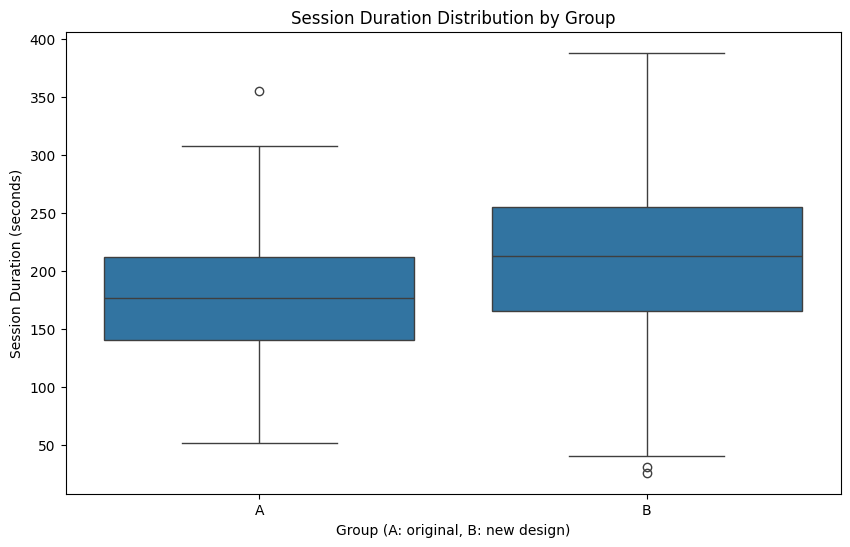

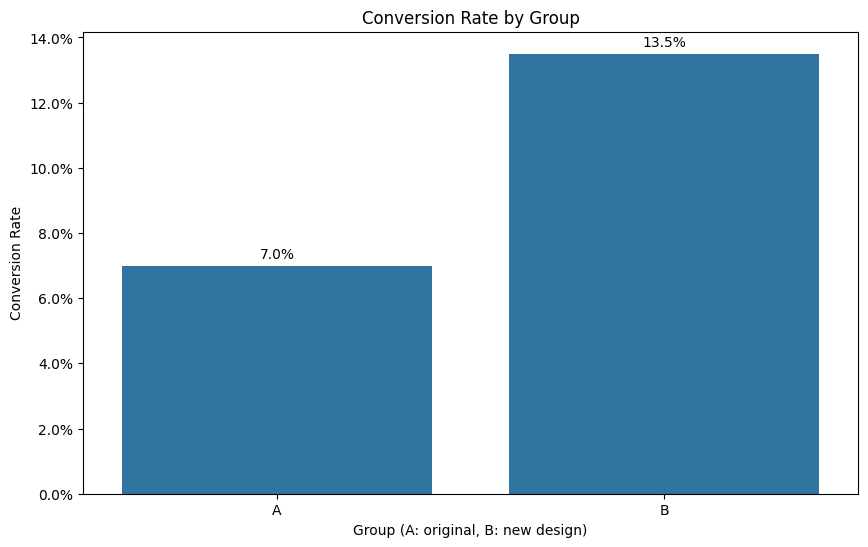

In [32]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Chart 1: session duration distribution by group (box plot or histogram)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='group', y='session_duration_sec', data=df, ax=ax)
ax.set_title('Session Duration Distribution by Group')
ax.set_xlabel('Group (A: original, B: new design)')
ax.set_ylabel('Session Duration (seconds)')
plt.show()

# Chart 2: conversion rate by group (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='group', y='converted', data=df, errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:.1%}' for v in container.datavalues], padding=3)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title('Conversion Rate by Group')
ax.set_xlabel('Group (A: original, B: new design)')
ax.set_ylabel('Conversion Rate')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Group B's sessions are **30.99** seconds longer (z-score **5.03**), and B views **0.63** more pages (z-score **3.54**).  
  (B그룹 세션이 **30.99**초 더 길고(z-score **5.03**), 조회 페이지도 **0.63** 더 많음(z-score **3.54**))
- Group B converts at **13.50%** against **7.00%**, and the 95% interval **[0.59%, 12.41%]** excludes zero.  
  (B그룹 전환율은 **13.50%** 대 **7.00%**이고, 95% 신뢰구간 **[0.59%, 12.41%]**은 0을 포함하지 않음)
- The conversion gap is uncertain: the interval ranges from **0.59** to **12.41** points.  
  (전환율 차이는 불확실함: 구간이 **0.59**~**12.41**%p에 걸쳐 있음)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Prefer the new design (Group B), since duration, pages, and conversion are all higher.  
   (체류시간, 페이지 수, 전환율이 모두 높으니 새 디자인(B그룹)을 선호)
2. Report the conversion gap as **6.50** points with its interval **[0.59%, 12.41%]**, not as one number.  
   (전환율 차이는 숫자 하나가 아니라 **6.50**%p와 구간 **[0.59%, 12.41%]**로 보고)
3. Collect more visitors than **200** per group to narrow the wide interval.  
   (넓은 구간을 좁히려면 그룹당 **200**명보다 더 많은 방문자를 모을 것)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- In Question 2, `ci_95` was only the margin (`1.96 * SE`), not an interval for the difference.  
  (Q2에서 `ci_95`가 차이의 구간이 아니라 오차범위(`1.96 * SE`)뿐이었음)
- Question 2 printed the z-score left over from Question 1.  
  (Q2가 Q1에서 남은 z-score를 출력하고 있었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- A confidence interval for a difference is (B − A) ± 1.96 × SE, and zero outside it means a significant gap.  
  (차이의 신뢰구간은 (B − A) ± 1.96 × SE이고, 0이 밖에 있으면 유의한 차이)
- The standard error of a difference of means is `sqrt(sd_a²/n_a + sd_b²/n_b)`, and the z-score is the difference divided by it.  
  (평균 차이의 표준오차는 `sqrt(sd_a²/n_a + sd_b²/n_b)`이고, z-score는 차이를 이것으로 나눈 값)
- For a 0/1 column, the variance is `p * (1 - p)`.  
  (0/1 컬럼의 분산은 `p * (1 - p)`)  

---
# 🧠 Reflection

**What was difficult?**  
Building the 95% confidence interval for the difference in conversion rates.  
(전환율 차이의 95% 신뢰구간 만들기)

**Why?**  
I stopped at the margin `1.96 * SE` and did not add and subtract it from the difference.  
(오차범위 `1.96 * SE`에서 멈추고 차이에 더하고 빼지 않았음)

**How did I solve it?**  
I computed the difference (B − A) and used difference ± margin as the lower and upper ends.  
(차이(B − A)를 구하고 차이 ± 오차범위를 하한과 상한으로 씀)

**What would I do differently next time?**  
Check that each printed number answers the question before moving on.  
(다음으로 넘어가기 전에 출력한 숫자가 질문에 답하는지 확인하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The z-scores and the interval now match the questions. Group B converts **6.50** points higher.  
(z-score와 신뢰구간이 이제 질문과 맞음. B그룹 전환율이 **6.50**%p 높음)  

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The confidence interval for the difference took the most work.  
(차이의 신뢰구간에 손이 가장 많이 갔음)  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 38 — Numpy stats  
  (NumPy로 통계 응용하기)  